In [1]:
import openmc
import numpy as np

In [2]:
# Material Definition

# When MCNP specifies a negative fraction, it is weight percent.
concrete = openmc.Material()
p = 'wo'
concrete.add_nuclide('H1',0.006,p)
concrete.add_nuclide('O16',0.5,p)
concrete.add_nuclide('Na23',0.017,p)
concrete.add_nuclide('Al27',0.048,p)
concrete.add_nuclide('Si28',0.28940,p)
concrete.add_nuclide('Si29',0.01518,p)
concrete.add_nuclide('Si30',0.01042,p)
concrete.add_element('K',0.019,p)
concrete.add_element('Ca',0.0830,p)
concrete.add_nuclide('Fe54',0.00068,p)
concrete.add_nuclide('Fe55',0.01106,p)
concrete.add_nuclide('Fe57',0.00026,p)
concrete.set_density('g/cc',2.35)

# stainless steel
ss202 = openmc.Material()
ss202.add_element('C',0.00075,p)
ss202.add_nuclide('N14',0.00125,p)
ss202.add_element('Si',0.00500,p)
ss202.add_nuclide('P31',0.0003,p)
ss202.add_element('P',0.00015,p)
ss202.add_element('Cr',0.18,p)
ss202.add_nuclide('Mn55',0.08750,p)
ss202.add_element('Fe',0.232,p)
ss202.add_element('Ni',0.05,p)
ss202.set_density('g/cc',7.86)

m12 = openmc.Material()
m12.add_nuclide('N14',0.755,p)
m12.add_nuclide('O16',0.232,p)
m12.add_element('Ar',0.013,p)
m12.set_density('g/cc',0.0012)

# m20, m21, m22 are dummy materials
materials = openmc.Materials([concrete,ss202,m12])

In [3]:
# Surface Specification
s1 = openmc.Sphere(x0=6,r=3)
s2 = openmc.Sphere(x0=-6,r=3)
s3 = openmc.Sphere(r=10,boundary_type='vacuum')

# Cell specification
c900 = openmc.Cell(fill=concrete,region=-s1)
c901 = openmc.Cell(fill=ss202, region=-s2)
c902 = openmc.Cell(fill=m12,region=+s1&+s2&-s3)
c903 = openmc.Cell(fill=None,region= +s3)

geometry = openmc.Geometry([c900,c901,c902,c903])

In [4]:
# Tally specification
mesh = openmc.RectilinearMesh(name='mesh/n-gamma')
mesh.x_grid=np.linspace(-10,10,50)
mesh.y_grid=np.linspace(-10,10,50)
mesh.z_grid=np.linspace(-10,10,50)

mesh_filter = openmc.MeshFilter(mesh)

fx4 = openmc.Tally()
fx4.name = 'n-gamma'
fx4.nuclides = ['Na23','Fe54','Mn55']
fx4.scores = ['(n,gamma)']
fx4.filters = [mesh_filter]

tallies = openmc.Tallies(tallies=[fx4])

In [5]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.Point() # the cell is spherical
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(2e6) # energy in eV 
settings.source = source

# 500,000 histories 
settings.particles = 1000
settings.batches = 500

In [6]:
model = openmc.model.Model(geometry, materials, settings, tallies)

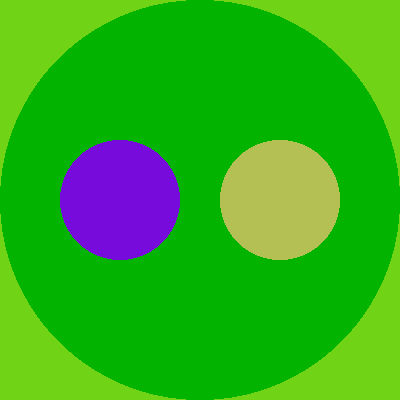

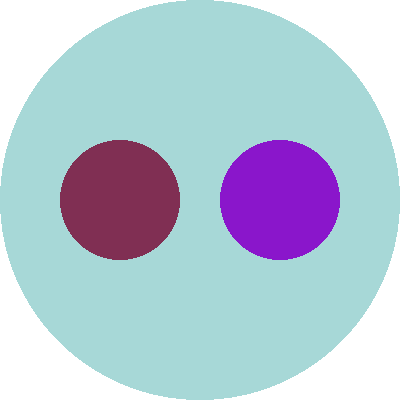

In [8]:
w = 20
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'material'
plots.append(plot)
openmc.plot_inline(plots)

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [20]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        print(sp.tallies[key])

Tally
	ID             =	1
	Name           =	n-gamma
	Filters        =	MeshFilter
	Nuclides       =	Na23 Fe54 Mn55
	Scores         =	['(n,gamma)']
	Estimator      =	tracklength
	Multiply dens. =	True


In [30]:
with openmc.StatePoint(sp_filename) as sp:
    results = sp.get_tally(name='n-gamma')
    df = results.get_pandas_dataframe()

    #'Na23'
    #df[df['nuclide']=='Na23']['mean'].sum()
    #print(f"} \pm {df[df['nuclide']=='Na23']['std. dev.'].sum()}")
    #print(df[df['nuclide']=='Fe54']['mean'].sum())
    #print(df[df['nuclide']=='Mn55']['mean'].sum())

Na23 (n,$\gamma$): 6.463718095198082e-08 $\pm$ 1.2132903657985641e-08
1.479026906500431e-06
7.593975885416255e-06


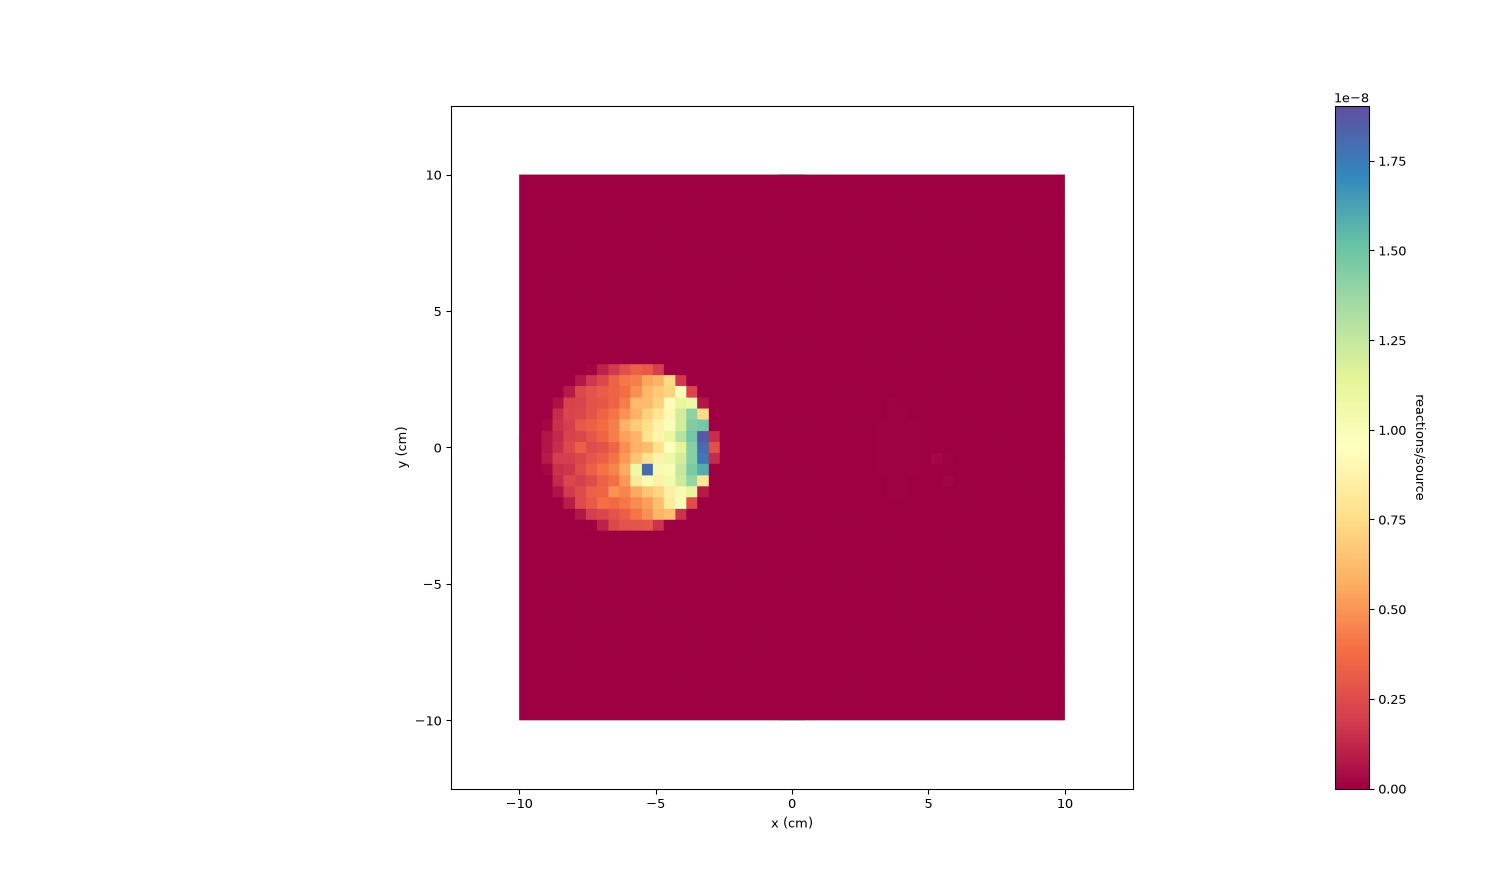 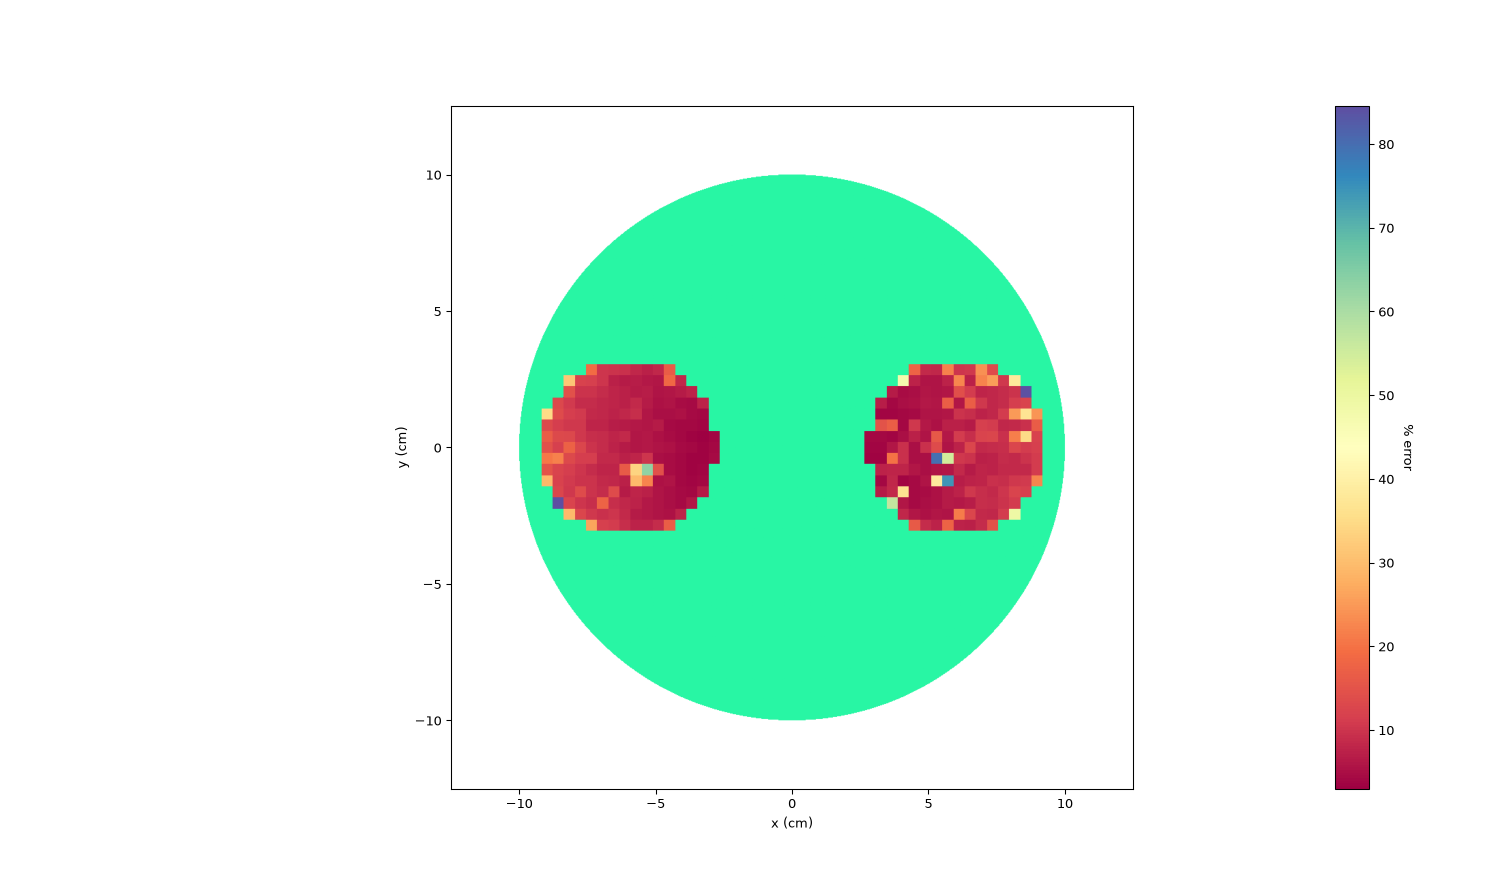